# 05 · 03 with weight decay 1e-5 (instead of 1e-4)


In [1]:
import os
import random
from pathlib import Path
import numpy as np
import pandas as pd
import torch

# torch.set_num_threads(8)
# print("PyTorch CPU threads:", torch.get_num_threads())

from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

from src.dataset.balanced_class_subset import BalancedClassSubset
from src.dataset.tiny_imagenet_dataset import TinyImageNetLoader, get_tiny_imagenet_class_names
from archive.utils import means, stds, convert_to_rgb, show_image, get_device, print_device_info
from archive.utils import apply_mixup, apply_cutmix

RESUME = False
SEED = 42
NUM_CLASSES = 200
TRAIN_PER_CLASS = 500
VAL_PER_CLASS = 50
BATCH_SIZE = 64
NUM_WORKERS = 4
EPOCHS = 100
INITIAL_LR = 0.05
MIN_LR = 1e-05
WEIGHT_DECAY = 0.00001
LABEL_SMOOTHING = 0.10
CLASSIFIER_DROPOUT = 0.20
CLEAN_EVAL_INTERVAL = 5

MIXUP_ALPHA = 0.2
CUTMIX_ALPHA = 1.0
CLEAN_PROB = 0.25
MIXUP_PROB = 0.375
CUTMIX_PROB = 0.375

assert abs(CLEAN_PROB + MIXUP_PROB + CUTMIX_PROB - 1.0) < 1e-12

SAVE_DIR = Path('checkpoints_05_wd1e5')
SAVE_DIR.mkdir(parents=True, exist_ok=True)

DEVICE = get_device()

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print('Device:', DEVICE)
print('DataLoader workers:', NUM_WORKERS)
print('Epochs:', EPOCHS)
print(f'Batch probabilities: Clean={CLEAN_PROB:.0%} | MixUp={MIXUP_PROB:.0%} | CutMix={CUTMIX_PROB:.0%}')
print(f'MixUp alpha={MIXUP_ALPHA} | CutMix alpha={CUTMIX_ALPHA}')

Device: mps
DataLoader workers: 4
Epochs: 100
Batch probabilities: Clean=25% | MixUp=38% | CutMix=38%
MixUp alpha=0.2 | CutMix alpha=1.0


In [2]:
print_device_info(DEVICE)

Number of MPS devices: 1


## 1. Local model and reference dataset loader

In [3]:
TINY_ROOT = Path('../../../data/tiny_imagenet/tiny-imagenet-200')
SELECTED_CLASSES = list(range(NUM_CLASSES))
print('Dataset root:', TINY_ROOT)

Dataset root: ../../data/tiny_imagenet/tiny-imagenet-200


In [4]:
train_tf = transforms.Compose([transforms.Lambda(convert_to_rgb), transforms.RandomCrop(64, padding=4, padding_mode='reflect'), transforms.RandomHorizontalFlip(p=0.5), transforms.RandAugment(num_ops=2, magnitude=5, interpolation=InterpolationMode.BILINEAR), transforms.ToTensor(), transforms.Normalize(mean=means, std=stds)])
test_tf = transforms.Compose([transforms.Lambda(convert_to_rgb), transforms.ToTensor(), transforms.Normalize(mean=means, std=stds)])

train_dataset, val_dataset, _, _ = TinyImageNetLoader(seed=SEED, root=TINY_ROOT, train_transform=train_tf, test_transform=test_tf).load()
clean_train_dataset, _, _, _ = TinyImageNetLoader(seed=SEED, root=TINY_ROOT, train_transform=test_tf, test_transform=test_tf).load()

if not hasattr(clean_train_dataset, 'transform'):
    raise AttributeError('Expected the dataset to expose a transform attribute.')

train_subset = BalancedClassSubset(train_dataset, SELECTED_CLASSES, TRAIN_PER_CLASS, seed=SEED)
clean_train_subset = BalancedClassSubset(clean_train_dataset, SELECTED_CLASSES, TRAIN_PER_CLASS, seed=SEED)
val_subset = BalancedClassSubset(val_dataset, SELECTED_CLASSES, VAL_PER_CLASS, seed=SEED + 1)

assert train_subset.samples == clean_train_subset.samples, 'Clean and augmented training subsets differ.'
assert len(train_subset) == NUM_CLASSES * TRAIN_PER_CLASS
assert len(val_subset) == NUM_CLASSES * VAL_PER_CLASS

FULL_CLASS_NAMES = get_tiny_imagenet_class_names(train_dataset, TINY_ROOT)
CLASS_NAMES = [FULL_CLASS_NAMES[i] for i in SELECTED_CLASSES]

print('Train:', len(train_subset), 'Validation:', len(val_subset))

Train: 100000 Validation: 10000


## 2. DataLoaders (macOS / Jupyter safe)

In [5]:
loader_generator = torch.Generator()
loader_generator.manual_seed(SEED)

loader_options = {'batch_size': BATCH_SIZE, 'num_workers': NUM_WORKERS, 'pin_memory': DEVICE.type == 'cuda', 'persistent_workers': NUM_WORKERS > 0, **({'prefetch_factor': 2} if NUM_WORKERS > 0 else {})}

train_loader = DataLoader(train_subset, shuffle=True, generator=loader_generator, **loader_options)
val_loader = DataLoader(val_subset, shuffle=False, **loader_options)
clean_train_loader = DataLoader(clean_train_subset, shuffle=False, **loader_options)

print('Training batches:', len(train_loader))
print('Validation batches:', len(val_loader))

Training batches: 1563
Validation batches: 157


## Visual Check

In [6]:
# NUM_SHOW = 5
#
# train_iter = iter(train_loader)
# clean_train_iter = iter(clean_train_loader)
# val_iter = iter(val_loader)

In [7]:
# train_images, train_labels = next(train_iter)
# clean_train_images, clean_train_labels = next(clean_train_iter)
# val_images, val_labels_batch = next(val_iter)
#
# show_image(train_images, train_labels, NUM_SHOW, CLASS_NAMES, name="Train Images", has_norm=True)
# show_image(clean_train_images, clean_train_labels, NUM_SHOW, CLASS_NAMES, name="Clean Train Images", has_norm=True)
# show_image(val_images, val_labels_batch, NUM_SHOW, CLASS_NAMES, name="Validation Images", has_norm=True)

In [8]:
# mixup_images, mixup_labels_a, mixup_labels_b, mixup_lam, _ = apply_mixup(train_images.clone(), train_labels.clone(), alpha=MIXUP_ALPHA)
# cutmix_images, cutmix_labels_a, cutmix_labels_b, cutmix_lam, _ = apply_cutmix(train_images.clone(), train_labels.clone(), alpha=CUTMIX_ALPHA)
#
# show_mixed_images(mixup_images, mixup_labels_a, mixup_labels_b, mixup_lam, CLASS_NAMES, NUM_SHOW, name="MixUp Images", has_norm=True)
# show_mixed_images(cutmix_images, cutmix_labels_a, cutmix_labels_b, cutmix_lam, CLASS_NAMES, NUM_SHOW, name="CutMix Images", has_norm=True)

## 3. Model, optimizer and cosine scheduler

In [9]:
from archive._01_z_cnn._04_cnn_double_gap_2level_with_3layer_parameter.model import StandardCNN

base_model = StandardCNN(num_classes=NUM_CLASSES, block3_dropout=0.05, block4_dropout=0.10, classifier_dropout=CLASSIFIER_DROPOUT)
print('Parameters:', sum(p.numel() for p in base_model.parameters()))
print('Architecture: 10Conv (2+2+3+3) | No final MaxPool | GAP -> 512 -> 512 -> 200')
assert sum(isinstance(m, nn.Conv2d) for m in base_model.modules()) == 10
assert not any(isinstance(m, nn.MaxPool2d) for m in base_model.level4.modules())

model = base_model.to(DEVICE)

def raw_model():
    return model

criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)
optimizer = torch.optim.SGD(model.parameters(), lr=INITIAL_LR, momentum=0.9, weight_decay=WEIGHT_DECAY, nesterov=True)

TOTAL_STEPS = EPOCHS * len(train_loader)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TOTAL_STEPS, eta_min=MIN_LR)

Parameters: 8003720
Architecture: 10Conv (2+2+3+3) | No final MaxPool | GAP -> 512 -> 512 -> 200


## 4. Best and latest checkpoints

In [10]:
BEST_PATH = SAVE_DIR / 'best_model.pth'
LATEST_PATH = SAVE_DIR / 'latest_checkpoint.pth'

history = {k: [] for k in ['epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc', 'clean_train_loss', 'clean_train_acc', 'lr', 'generalization_gap']}

best_acc = -1.0
best_epoch = 0
start_epoch = 1

def rng_state():
    return dict(python=random.getstate(), numpy=np.random.get_state(), torch=torch.get_rng_state(), cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None, loader=loader_generator.get_state())

def restore_rng(s):
    random.setstate(s['python'])
    np.random.set_state(s['numpy'])
    torch.set_rng_state(s['torch'])
    if torch.cuda.is_available() and s.get('cuda') is not None:
        torch.cuda.set_rng_state_all(s['cuda'])
    loader_generator.set_state(s['loader'])

def save_latest(epoch):
    payload = dict(epoch=epoch, model=raw_model().state_dict(), optimizer=optimizer.state_dict(), scheduler=scheduler.state_dict(), history=history, best_acc=best_acc, best_epoch=best_epoch, rng=rng_state(), config=dict(num_classes=NUM_CLASSES, batch_size=BATCH_SIZE, epochs=EPOCHS, train_per_class=TRAIN_PER_CLASS, val_per_class=VAL_PER_CLASS, classifier='10conv_no_final_pool_dense_fc', classifier_dropout=CLASSIFIER_DROPOUT, augmentation='randaugment_2_5_25clean_375mixup_375cutmix', mixup_alpha=MIXUP_ALPHA, cutmix_alpha=CUTMIX_ALPHA, clean_prob=CLEAN_PROB, mixup_prob=MIXUP_PROB, cutmix_prob=CUTMIX_PROB))
    temp = LATEST_PATH.with_suffix('.tmp')
    torch.save(payload, temp)
    os.replace(temp, LATEST_PATH)

if RESUME:
    ck = torch.load(LATEST_PATH, map_location='cpu', weights_only=False)
    cfg = ck['config']

    if cfg['batch_size'] != BATCH_SIZE or cfg['epochs'] != EPOCHS or cfg.get('classifier') != '10conv_no_final_pool_dense_fc' or cfg.get('classifier_dropout') != CLASSIFIER_DROPOUT or cfg.get('augmentation') != 'randaugment_3_7_25clean_375mixup_375cutmix' or cfg.get('mixup_alpha') != MIXUP_ALPHA or cfg.get('cutmix_alpha') != CUTMIX_ALPHA or cfg.get('clean_prob') != CLEAN_PROB or cfg.get('mixup_prob') != MIXUP_PROB or cfg.get('cutmix_prob') != CUTMIX_PROB:
        raise ValueError('Resume configuration does not match this GAP + 25% Clean + 37.5% MixUp + 37.5% CutMix experiment.')

    raw_model().load_state_dict(ck['model'])
    optimizer.load_state_dict(ck['optimizer'])
    scheduler.load_state_dict(ck['scheduler'])

    for state in optimizer.state.values():
        for k, v in state.items():
            if torch.is_tensor(v):
                state[k] = v.to(DEVICE)

    history = ck['history']
    best_acc = ck['best_acc']
    best_epoch = ck['best_epoch']
    start_epoch = ck['epoch'] + 1
    restore_rng(ck['rng'])

    print(f'Resuming from epoch {start_epoch} | LR = {scheduler.get_last_lr()[0]:.10f}')
else:
    print('Starting fresh 10Conv + No Final Pool + Dense + 25% Clean + 37.5% MixUp + 37.5% CutMix training from epoch 1.')

Starting fresh 10Conv + No Final Pool + Dense + 25% Clean + 37.5% MixUp + 37.5% CutMix training from epoch 1.


## 5. 25% Clean + 37.5% MixUp + 37.5% CutMix training and validation

In [11]:
def choose_batch_augmentation(images, labels):
    r = np.random.random()
    if r < CLEAN_PROB:
        return images, labels, labels, 1.0, 'Clean'
    if r < CLEAN_PROB + MIXUP_PROB:
        return apply_mixup(images, labels, alpha=MIXUP_ALPHA)
    return apply_cutmix(images, labels, alpha=CUTMIX_ALPHA)

def run_epoch(loader, training=False):
    if training:
        model.train()
    else:
        model.eval()

    total_loss = torch.zeros((), device=DEVICE)
    total_correct = torch.zeros((), device=DEVICE)
    total = 0
    clean_batches = 0
    mixup_batches = 0
    cutmix_batches = 0
    context = torch.enable_grad() if training else torch.inference_mode()

    with context:
        for images, labels in tqdm(loader, leave=False, desc='Train' if training else 'Eval'):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            if training:
                optimizer.zero_grad(set_to_none=True)
                model_images, labels_a, labels_b, lam, batch_type = choose_batch_augmentation(images, labels)

                if batch_type == 'Clean':
                    clean_batches += 1
                elif batch_type == 'MixUp':
                    mixup_batches += 1
                else:
                    cutmix_batches += 1

                logits = model(model_images)

                if batch_type == 'Clean':
                    loss = criterion(logits, labels)
                    correct = (logits.detach().argmax(dim=1) == labels).sum()
                else:
                    loss = lam * criterion(logits, labels_a) + (1.0 - lam) * criterion(logits, labels_b)
                    predictions = logits.detach().argmax(dim=1)
                    correct = lam * (predictions == labels_a).sum() + (1.0 - lam) * (predictions == labels_b).sum()

                loss.backward()
                optimizer.step()
                scheduler.step()
            else:
                logits = model(images)
                loss = criterion(logits, labels)
                correct = (logits.detach().argmax(dim=1) == labels).sum()

            batch_size = labels.size(0)
            total += batch_size
            total_loss += loss.detach() * batch_size
            total_correct += correct

    avg_loss = (total_loss / total).item()
    accuracy = (total_correct * (100.0 / total)).item()

    if training:
        print(f'Batch selection: Clean={clean_batches}, MixUp={mixup_batches}, CutMix={cutmix_batches}')

    return avg_loss, accuracy

In [12]:
for epoch in tqdm(range(start_epoch, EPOCHS + 1)):
    train_loss, train_acc = run_epoch(train_loader, training=True)

    if epoch == 1 or epoch % CLEAN_EVAL_INTERVAL == 0:
        clean_train_loss, clean_train_acc = run_epoch(clean_train_loader, training=False)
    else:
        clean_train_loss, clean_train_acc = None, None

    val_loss, val_acc = run_epoch(val_loader, training=False)
    current_lr = optimizer.param_groups[0]['lr']

    epoch_metrics = {'epoch': epoch, 'train_loss': train_loss, 'train_acc': train_acc, 'val_loss': val_loss, 'val_acc': val_acc, 'clean_train_loss': clean_train_loss, 'clean_train_acc': clean_train_acc, 'lr': current_lr, 'generalization_gap': clean_train_acc - val_acc if clean_train_acc is not None else None}

    for name, value in epoch_metrics.items():
        history[name].append(value)

    if val_acc > best_acc:
        best_acc = val_acc
        best_epoch = epoch
        torch.save({'model': raw_model().state_dict(), 'epoch': epoch, 'val_acc': val_acc, 'class_names': CLASS_NAMES, 'experiment': '10Conv ReLU + No Final Pool + Dense + 25% Clean + 37.5% MixUp + 37.5% CutMix'}, BEST_PATH)

    save_latest(epoch)

    clean_text = f'{clean_train_acc:.2f}% / {clean_train_loss:.4f}' if clean_train_acc is not None else 'Skipped'
    print(f'Epoch {epoch:03d}/{EPOCHS} | Train: {train_acc:.2f}% / {train_loss:.4f} | Val: {val_acc:.2f}% / {val_loss:.4f} | Clean Train: {clean_text} | LR: {current_lr:.7f} | Best: {best_acc:.2f}% (epoch {best_epoch})')

print(f'Training finished at epoch {EPOCHS}. Best validation accuracy: {best_acc:.2f}% (epoch {best_epoch})')

  0%|          | 0/100 [00:00<?, ?it/s]

Train:   0%|          | 0/1563 [00:07<?, ?it/s]

Batch selection: Clean=410, MixUp=576, CutMix=577


Eval:   0%|          | 0/1563 [00:06<?, ?it/s]

Eval:   0%|          | 0/157 [00:04<?, ?it/s]

Epoch 001/100 | Train: 3.52% / 4.9890 | Val: 7.51% / 4.5806 | Clean Train: 7.83% / 4.5819 | LR: 0.0499877 | Best: 7.51% (epoch 1)


... (412 outputs left out)

Batch selection: Clean=415, MixUp=569, CutMix=579


Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

Eval:   0%|          | 0/157 [00:00<?, ?it/s]

Epoch 100/100 | Train: 70.67% / 2.2148 | Val: 64.21% / 2.2019 | Clean Train: 98.14% / 1.0755 | LR: 0.0000100 | Best: 64.54% (epoch 89)
Training finished at epoch 100. Best validation accuracy: 64.54% (epoch 89)


## 6. Training and validation curves

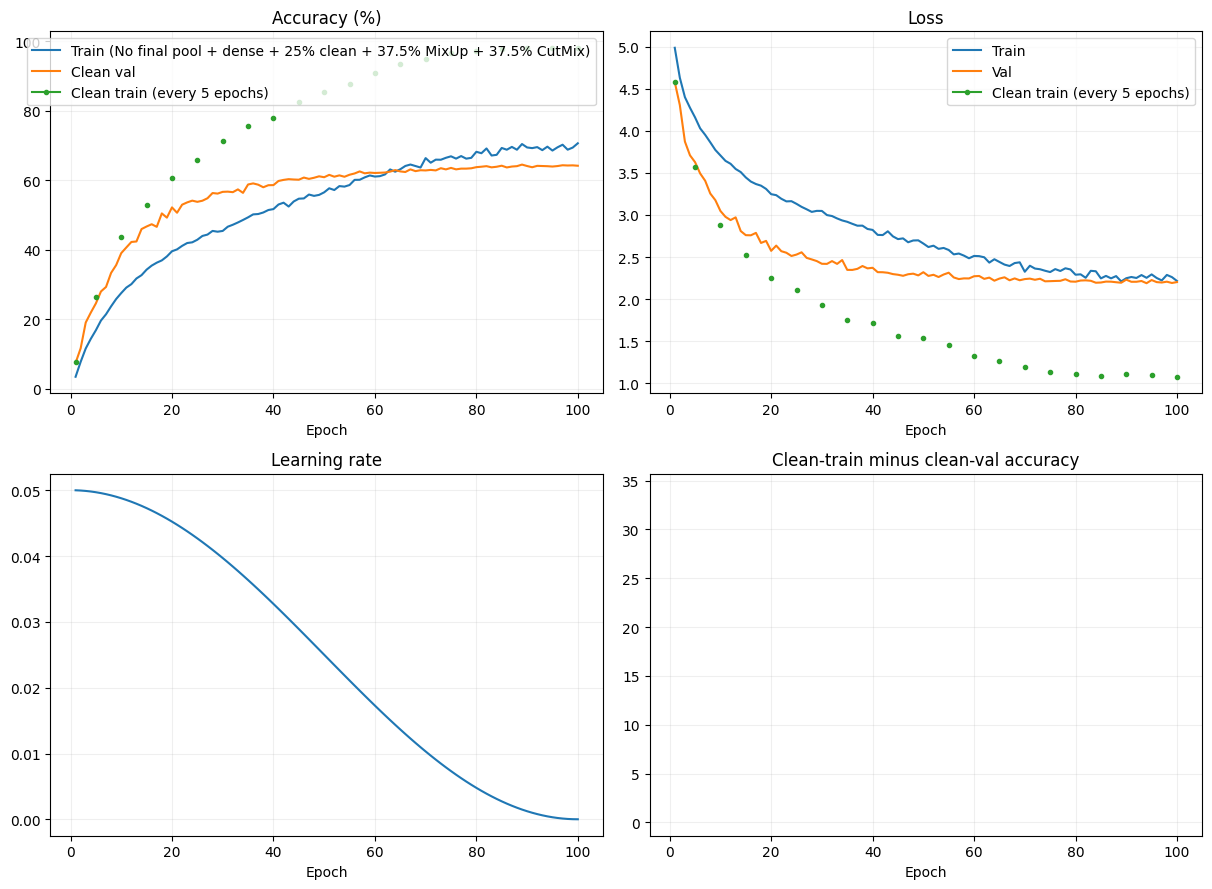

Eval:   0%|          | 0/1563 [00:00<?, ?it/s]

In [ ]:
h = pd.DataFrame(history)
fig, axs = plt.subplots(2, 2, figsize=(13, 9))

axs[0, 0].plot(h.epoch, h.train_acc, label='Train (No final pool + dense + 25% clean + 37.5% MixUp + 37.5% CutMix)')
axs[0, 0].plot(h.epoch, h.val_acc, label='Clean val')
axs[0, 0].plot(h.epoch, h.clean_train_acc, label='Clean train (every 5 epochs)', marker='o', markersize=3)
axs[0, 0].set_title('Accuracy (%)')
axs[0, 0].legend()

axs[0, 1].plot(h.epoch, h.train_loss, label='Train')
axs[0, 1].plot(h.epoch, h.val_loss, label='Val')
axs[0, 1].plot(h.epoch, h.clean_train_loss, label='Clean train (every 5 epochs)', marker='o', markersize=3)
axs[0, 1].set_title('Loss')
axs[0, 1].legend()

axs[1, 0].plot(h.epoch, h.lr)
axs[1, 0].set_title('Learning rate')

axs[1, 1].plot(h.epoch, h.generalization_gap)
axs[1, 1].set_title('Clean-train minus clean-val accuracy')

for ax in axs.flat:
    ax.set_xlabel('Epoch')
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

best = torch.load(BEST_PATH, map_location='cpu', weights_only=False)
raw_model().load_state_dict(best['model'])
model.eval()

clean_train_loss, clean_train_acc = run_epoch(clean_train_loader)
clean_val_loss, clean_val_acc = run_epoch(val_loader)

print(f'Best checkpoint: clean train {clean_train_acc:.2f}%, clean val {clean_val_acc:.2f}%, gap {clean_train_acc - clean_val_acc:.2f} pp')